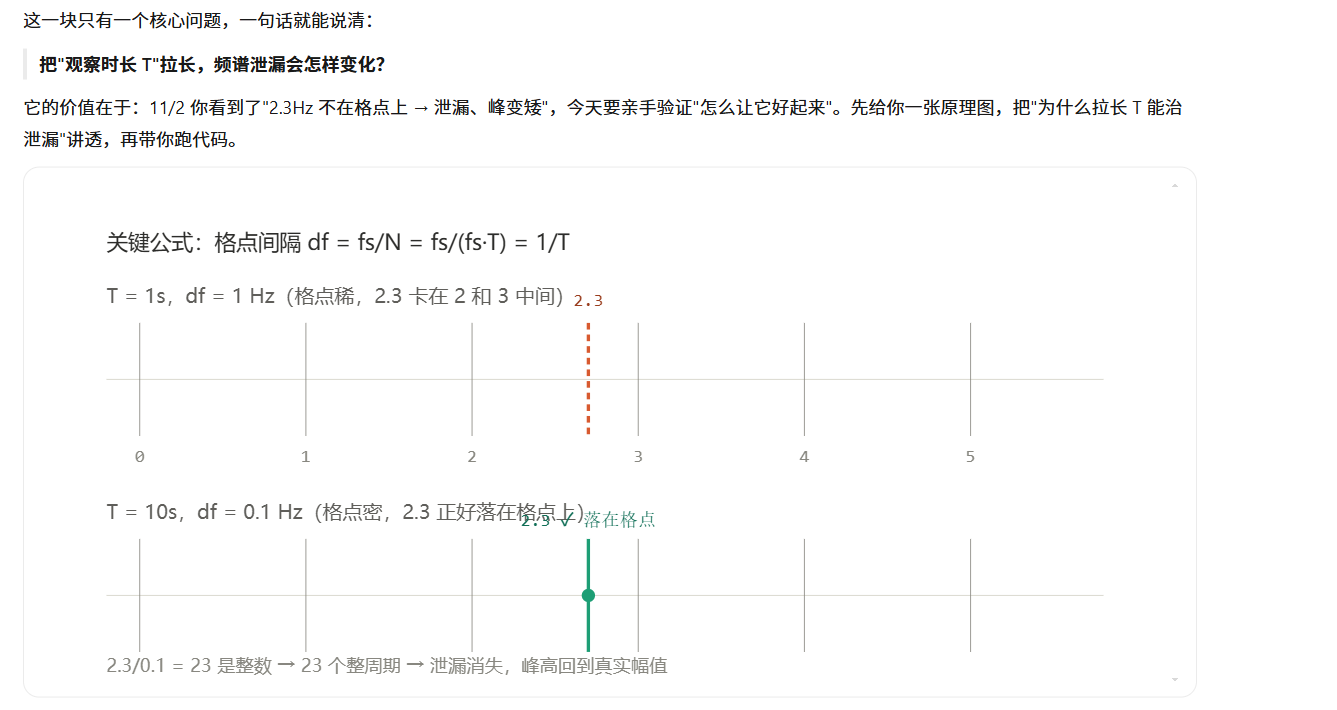

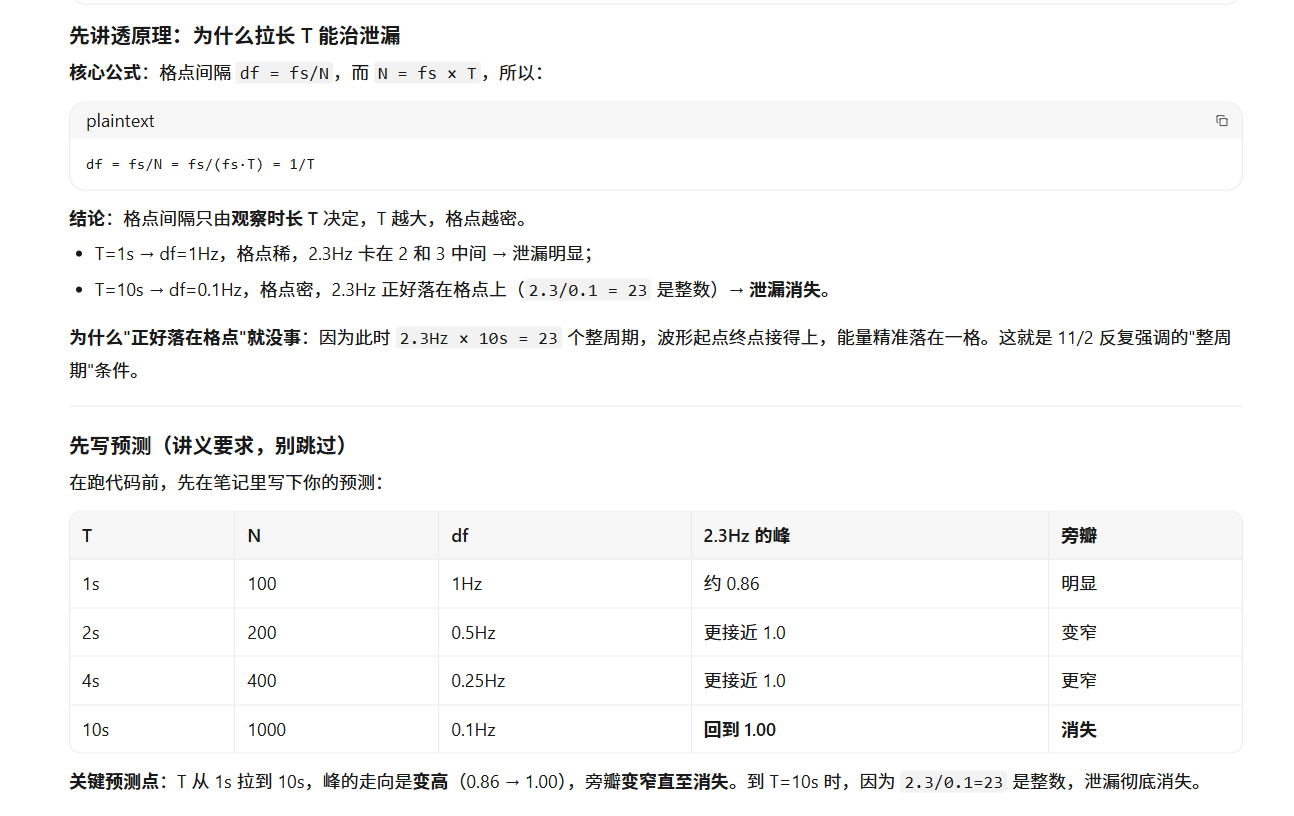

T=1s  N= 100  df=1.00Hz   峰@2.00Hz  峰值=0.871
T=2s  N= 200  df=0.50Hz   峰@2.50Hz  峰值=0.729
T=4s  N= 400  df=0.25Hz   峰@2.25Hz  峰值=0.931
T=10s  N=1000  df=0.10Hz   峰@2.30Hz  峰值=1.000


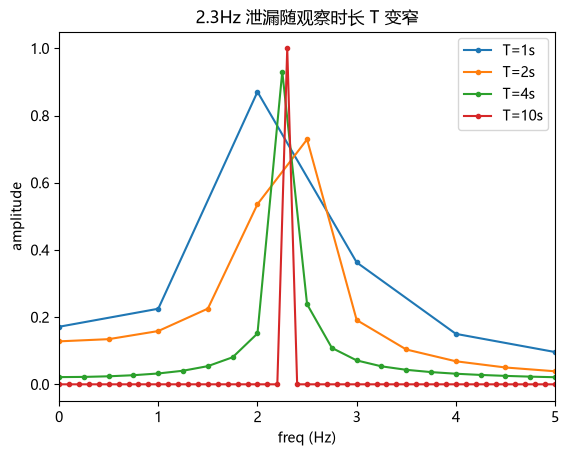

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

fs = 100
f0 = 2.3
for T in (1.0, 2.0, 4.0, 10.0):
    N = int(fs * T)
    t = np.arange(0, T, 1/fs)
    x = np.sin(2*np.pi*f0*t)
    X = np.fft.rfft(x)
    fr = np.fft.rfftfreq(N, d=1/fs)
    a = np.abs(X) * 2 / N
    peak = a.max(); peak_f = fr[a.argmax()]
    print(f"T={T:.0f}s  N={N:>4d}  df={fs/N:.2f}Hz   峰@{peak_f:.2f}Hz  峰值={peak:.3f}")
    plt.plot(fr, a, marker="o", ms=3, label=f"T={T:.0f}s")
plt.xlim(0, 5); plt.xlabel("freq (Hz)"); plt.ylabel("amplitude"); plt.legend()
plt.title("2.3Hz 泄漏随观察时长 T 变窄")
plt.show()


-   拉长观察时长T，频率格点变密（fs/N=1/T，变小），泄露变窄，当信号频率刚好落在格点上且是整周期的时候，泄露消失，峰高回到真实幅值1.00
-   实际工程里这就是"采集更长的数据 / 选合适的采样点数"来对齐频率的思路。

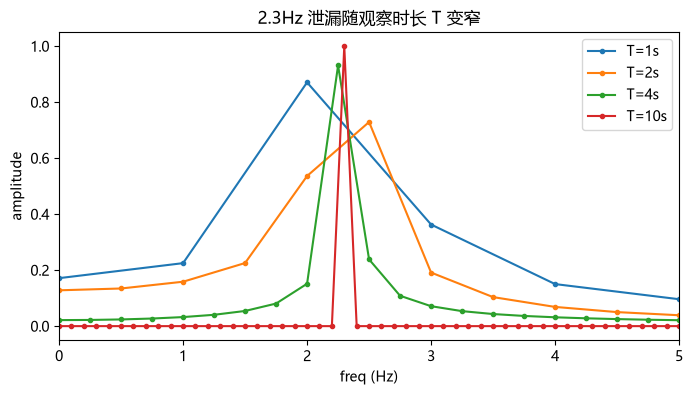

In [3]:
from pathlib import Path

fig = plt.figure(figsize=(8, 4))
for T in (1.0, 2.0, 4.0, 10.0):
    N = int(fs * T)
    t = np.arange(0, T, 1/fs)
    x = np.sin(2*np.pi*f0*t)
    X = np.fft.rfft(x)
    fr = np.fft.rfftfreq(N, d=1/fs)
    a = np.abs(X) * 2 / N
    plt.plot(fr, a, marker="o", ms=3, label=f"T={T:.0f}s")
plt.xlim(0, 5); plt.xlabel("freq (Hz)"); plt.ylabel("amplitude"); plt.legend()
plt.title("2.3Hz 泄漏随观察时长 T 变窄")
out = Path(r"E:\develop\Graduate_AI\learning-lab\results\day1103")
out.mkdir(exist_ok=True)
plt.savefig(out / "leak_vs_T.png", dpi=120)
plt.show()


真实超声里"观察时长"对应"一次采集的时间窗长度"：窗口越长，频域分辨率越高、越能分清相邻频率（如谐波和基频），代价是时间分辨率下降——这是信号处理里最经典的时频折中，波束形成、多普勒测速都踩在它上面。